# Laboratorul 5 — Stable Diffusion în practică

**Obiectiv:** măsurăm prin experimente controlate cum influențează setările unui model text→imagine (Stable Diffusion 1.5) **calitatea**, **potrivirea cu textul** (scorul CLIP) și **timpul de generare**.

| Sarcina | Conținut |
|---|---|
| 1 | Pregătirea și cele 9 imagini de bază |
| 2 | Instrumentele de măsurare: scorul CLIP, timpul, funcția `ruleaza(config)` |
| 3 | Experimentele A–E (ghidare, pași, metoda de eșantionare, seed, prompt negativ) |
| 4 | Recomandarea: o configurație pentru calitate și una pentru viteză |
| Bonus | img2img cu `strength` = 0,3 / 0,6 / 0,9 și legătura cu Laboratorul 4 |

**Note practice:**
- Notebook-ul merge **pe GPU** (float16, cum cere laboratorul) sau **pe CPU** (float32, deoarece float16 pe CPU e foarte lent sau nesuportat). Dispozitivul se alege automat.
- Pe CPU, generarea durează mult (zeci de secunde pe imagine; în total câteva ore — estimare). De aceea **fiecare experiment se salvează pe disc** în `lab5_outputs/<experiment>/` (imagini PNG + `meta.json` cu timpi și scoruri CLIP). Dacă reporniți kernelul, experimentele terminate se reîncarcă din cache. Pentru a le regenera, setați `RECOMPUTE = True`.
- Regula de aur a laboratorului: **pornim mereu de la configurația de bază și schimbăm un singur parametru**.

## Pasul 1. Importuri, dispozitiv și setări generale

- `DEVICE` / `DTYPE`: GPU + float16 dacă există CUDA, altfel CPU + float32.
- `sync()` înlocuiește `torch.cuda.synchronize()`: pe GPU așteaptă terminarea calculelor (altfel cronometrul ar măsura doar lansarea lor), pe CPU nu face nimic.
- `make_generator(seed)` înlocuiește `torch.Generator("cuda").manual_seed(seed)` și merge pe orice dispozitiv.
- `torch.manual_seed(42)` fixează seed-ul global.

## Pasul 0. Instalarea bibliotecilor (Sarcina 1.1)

Din mediul `lstm-lab` lipsesc `diffusers`, `accelerate` și `torchmetrics` (`transformers` există deja). Instalați-le o singură dată în terminal:

```bash
micromamba activate lstm-lab
pip install diffusers accelerate torchmetrics
```

Celula de mai jos verifică ce versiuni sunt instalate.

In [1]:
import importlib.metadata as md
for pkg in ["torch", "diffusers", "transformers", "accelerate", "torchmetrics"]:
    try:
        print(f"{pkg:13s} {md.version(pkg)}")
    except md.PackageNotFoundError:
        print(f"{pkg:13s} LIPSEȘTE  ->  pip install {pkg}")

torch         2.11.0+cu130
diffusers     0.42.0
transformers  5.20.2
accelerate    1.15.0
torchmetrics  1.9.0


In [2]:
import os, json, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image
from IPython.display import display

from diffusers import (StableDiffusionPipeline, StableDiffusionImg2ImgPipeline,
                       DDIMScheduler, DPMSolverMultistepScheduler, EulerDiscreteScheduler)
from transformers import CLIPModel, CLIPProcessor
from torchmetrics.functional.multimodal import clip_score

torch.manual_seed(42)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32
if DEVICE == "cpu":
    torch.set_num_threads(os.cpu_count())

OUT = Path("lab5_outputs")
OUT.mkdir(exist_ok=True)
RECOMPUTE = False   # True = regenerează tot, ignorând cache-ul de pe disc

def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def make_generator(seed):
    return torch.Generator(device=DEVICE).manual_seed(int(seed))

print(f"Dispozitiv: {DEVICE} | precizie: {DTYPE} | fire CPU: {torch.get_num_threads()}")

Dispozitiv: cuda | precizie: torch.float16 | fire CPU: 1


## Sarcina 1.2. Încărcarea modelului Stable Diffusion 1.5

`StableDiffusionPipeline` grupează componentele modelului:
- **encoderul de text CLIP**: transformă promptul în vectori de condiționare;
- **U-Net-ul**: prezice zgomotul în spațiul latent (64×64×4), la fel ca rețeaua din Laboratorul 4, dar condiționat și de text;
- **VAE-ul**: decodează latentul final în imaginea de 512×512;
- **schedulerul**: metoda de eșantionare (implicit `PNDMScheduler` la SD 1.5);
- **safety checker-ul**: înlocuiește cu o imagine neagră ce consideră NSFW (rar, dar se poate întâmpla din greșeală; marcăm asemenea cazuri).

Prima rulare descarcă ~4–5 GB în cache-ul Hugging Face. Salvăm configurația schedulerului implicit ca să o putem restaura după experimentul C.

In [3]:
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"

pipe = StableDiffusionPipeline.from_pretrained(MODEL_ID, torch_dtype=DTYPE)
pipe = pipe.to(DEVICE)
pipe.set_progress_bar_config(disable=True)

DEFAULT_SCHEDULER_CLASS = type(pipe.scheduler)
DEFAULT_SCHEDULER_CONFIG = pipe.scheduler.config
print("Scheduler implicit:", DEFAULT_SCHEDULER_CLASS.__name__)

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Scheduler implicit: PNDMScheduler


## Sarcina 1.3–1.4. Prompturile și configurația de bază

- 3 prompturi în engleză (limba de antrenare a modelului) × 3 seed-uri (42, 7, 123) = 9 imagini pe configurație.
- Configurația de bază: 30 de pași, ghidare 7,5, 512×512, scheduler implicit, fără prompt negativ.
- `set_scheduler(nume)` schimbă metoda de eșantionare cu `X.from_config(...)`, cum cere experimentul C; `None` revine la cea implicită.

In [6]:
PROMPTS = {
    "P1": "a watercolor painting of a red fox in a snowy forest",
    "P2": "a photo of a modern library interior, natural light",
    "P3": "a cartoon robot reading a book, flat illustration",
}
SEEDS = [42, 7, 123]
HEIGHT = WIDTH = 512

BASE = {"steps": 30, "guidance": 7.5, "negative_prompt": None, "scheduler": None}

SCHEDULERS = {
    "DDIM": DDIMScheduler,
    "DPMSolver": DPMSolverMultistepScheduler,
    "Euler": EulerDiscreteScheduler,
}

def set_scheduler(nume=None):
    cls = DEFAULT_SCHEDULER_CLASS if nume is None else SCHEDULERS[nume]
    pipe.scheduler = cls.from_config(DEFAULT_SCHEDULER_CONFIG)

## Sarcina 2.2. Generarea unei imagini și măsurarea timpului

`genereaza(...)` produce o singură imagine și măsoară timpul cu `time.perf_counter()`, apelând `sync()` înainte de fiecare citire a ceasului.

**Încălzirea:** prima generare după încărcare (sau după schimbarea schedulerului) e mai lentă, pentru că se alocă memorie și se inițializează kernelurile. De aceea `incalzire()` face o generare scurtă, care nu intră în măsurători.

In [7]:
def genereaza(prompt, seed, steps, guidance, negative_prompt=None):
    sync()
    t0 = time.perf_counter()
    out = pipe(prompt,
               num_inference_steps=steps,
               guidance_scale=guidance,
               negative_prompt=negative_prompt,
               height=HEIGHT, width=WIDTH,
               generator=make_generator(seed))
    sync()
    dt = time.perf_counter() - t0
    flags = getattr(out, "nsfw_content_detected", None)
    nsfw = bool(flags[0]) if flags else False
    return out.images[0], dt, nsfw

def incalzire(steps=4):
    # Generare de încălzire: rezultatul și timpul ei sunt ignorate.
    genereaza(PROMPTS["P1"], 0, steps, BASE["guidance"])

## Sarcina 2.1. Scorul CLIP

Scorul CLIP măsoară cât de bine se potrivește imaginea cu textul:
$\text{CLIPScore} = \max(100 \cdot \cos(E_{img}, E_{text}), 0)$, unde $E$ sunt reprezentările date de modelul CLIP. **Mai mare = potrivire mai bună.**

Folosim `clip_score` din `torchmetrics.functional.multimodal` cu modelul `openai/clip-vit-base-patch16`. Încărcăm modelul **o singură dată** și îl dăm funcției printr-o funcție care întoarce `(model, procesor)`. Altfel, modelul s-ar reîncărca la fiecare imagine. Dacă versiunea voastră de `torchmetrics` nu acceptă asta, celula trece automat pe varianta cu numele modelului (corectă, doar mai lentă).

Calculăm scorul **pe fiecare imagine în parte**, ca să putem raporta și abaterea standard. Testul de la final trebuie să dea un scor clar mai mare pentru textul potrivit.

In [9]:
CLIP_ID = "openai/clip-vit-base-patch16"
clip_model = CLIPModel.from_pretrained(CLIP_ID).eval()
clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)

def _clip_loader():
    return clip_model, clip_processor

def _to_tensor(img):
    # PIL -> tensor uint8 [3, H, W], formatul așteptat de clip_score
    return torch.from_numpy(np.array(img.convert("RGB"))).permute(2, 0, 1).contiguous()

def _as_tensor(feat):
    # transformers 5.x poate întoarce un obiect de tip ModelOutput în loc de tensor
    if isinstance(feat, torch.Tensor):
        return feat
    for attr in ("image_embeds", "text_embeds", "pooler_output"):
        if getattr(feat, attr, None) is not None:
            return getattr(feat, attr)
    return feat[0]

@torch.no_grad()
def _clip_manual(img, prompt):
    # Aceeași formulă ca torchmetrics: max(100 * cos(E_img, E_text), 0)
    inp = clip_processor(text=[prompt], images=[img.convert("RGB")], return_tensors="pt",
                         padding=True, truncation=True, max_length=77)
    e_img = _as_tensor(clip_model.get_image_features(pixel_values=inp["pixel_values"]))
    e_txt = _as_tensor(clip_model.get_text_features(input_ids=inp["input_ids"],
                                                    attention_mask=inp["attention_mask"]))
    e_img = e_img / e_img.norm(dim=-1, keepdim=True)
    e_txt = e_txt / e_txt.norm(dim=-1, keepdim=True)
    return float((100 * (e_img * e_txt).sum(-1)).clamp(min=0).item())

_test_img = Image.new("RGB", (512, 512), (220, 30, 30))

CLIP_MODE = None
for mode, fn in [("torchmetrics (model preîncărcat)",
                  lambda im, p: float(clip_score(_to_tensor(im), p, model_name_or_path=_clip_loader))),
                 ("torchmetrics (nume model)",
                  lambda im, p: float(clip_score(_to_tensor(im), p, model_name_or_path=CLIP_ID))),
                 ("implementare directă (aceeași formulă)", _clip_manual)]:
    try:
        fn(_test_img, "a red square")
        CLIP_MODE, _clip_fn = mode, fn
        break
    except Exception as e:
        print(f"[{mode}] nu merge: {type(e).__name__}: {e}")

print("Scor CLIP calculat prin:", CLIP_MODE)

@torch.no_grad()
def scor_clip(img, prompt):
    return _clip_fn(img, prompt)

print("Test — pătrat roșu vs 'a red square':     ", round(scor_clip(_test_img, "a red square"), 2))
print("Test — pătrat roșu vs 'a photo of a dog': ", round(scor_clip(_test_img, "a photo of a dog"), 2))

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[torchmetrics (model preîncărcat)] nu merge: AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'norm'


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

[torchmetrics (nume model)] nu merge: AttributeError: 'BaseModelOutputWithPooling' object has no attribute 'norm'
Scor CLIP calculat prin: implementare directă (aceeași formulă)
Test — pătrat roșu vs 'a red square':      28.26
Test — pătrat roșu vs 'a photo of a dog':  22.44


## Sarcina 2.3. Funcția `ruleaza(config)` și utilitarele pentru figuri

`ruleaza(config, eticheta)`:
1. pornește de la `BASE` și suprascrie **doar** cheile din `config` (un singur parametru schimbat);
2. setează schedulerul și face încălzirea;
3. generează cele 9 imagini (3 prompturi × 3 seed-uri), măsurând timpul și scorul CLIP pentru fiecare;
4. salvează imaginile și `meta.json` în `lab5_outputs/<eticheta>/`, apoi revine la schedulerul implicit;
5. întoarce **scorul CLIP mediu, abaterea standard, timpul mediu pe imagine și grila de imagini**.

Abaterea standard e cea de eșantion (`ddof=1`), adică cât variază scorul de la un prompt sau seed la altul.

Tot aici sunt funcțiile pentru grile, figuri comparative, grafice cu bare de eroare și tabelul de rezultate.

In [10]:
def grila_pil(imagini, ncols, dim=256):
    imagini = [im.resize((dim, dim)) for im in imagini]
    nrows = int(np.ceil(len(imagini) / ncols))
    grila = Image.new("RGB", (ncols * dim, nrows * dim), "white")
    for i, im in enumerate(imagini):
        grila.paste(im, ((i % ncols) * dim, (i // ncols) * dim))
    return grila

def arata_imagini(imagini, titluri, ncols, titlu_fig, fisier=None, dim=3.0):
    nrows = int(np.ceil(len(imagini) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(dim * ncols, dim * nrows + 0.6), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, im, t in zip(axes.flat, imagini, titluri):
        ax.imshow(im)
        ax.set_title(t, fontsize=9)
    fig.suptitle(titlu_fig, fontsize=12)
    fig.tight_layout()
    if fisier:
        fig.savefig(OUT / fisier, dpi=120, bbox_inches="tight")
    plt.show()

def ruleaza(config=None, eticheta="baza", prompts=None, seeds=None, incalzire_inainte=True):
    cfg = {**BASE, **(config or {})}
    prompts = prompts or PROMPTS
    seeds = list(seeds or SEEDS)
    folder = OUT / eticheta
    meta_path = folder / "meta.json"

    if meta_path.exists() and not RECOMPUTE:
        meta = json.loads(meta_path.read_text(encoding="utf-8"))
        print(f"[{eticheta}] încărcat din cache ({len(meta['rows'])} imagini)")
    else:
        folder.mkdir(parents=True, exist_ok=True)
        set_scheduler(cfg["scheduler"])
        try:
            if incalzire_inainte:
                incalzire()
            rows, t_total = [], time.perf_counter()
            for pid, prompt in prompts.items():
                for seed in seeds:
                    img, dt, nsfw = genereaza(prompt, seed, cfg["steps"], cfg["guidance"], cfg["negative_prompt"])
                    fname = f"{pid}_s{seed}.png"
                    img.save(folder / fname)
                    rows.append({"prompt_id": pid, "prompt": prompt, "seed": int(seed), "file": fname,
                                 "time_s": dt, "clip": scor_clip(img, prompt), "nsfw": nsfw})
                    print(f"  [{eticheta}] {pid} seed {seed}: {dt:6.1f} s | CLIP {rows[-1]['clip']:.2f}"
                          + ("  (NSFW detectat -> imagine neagră!)" if nsfw else ""))
        finally:
            set_scheduler(None)
        meta = {"eticheta": eticheta, "config": cfg, "rows": rows}
        meta_path.write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
        print(f"[{eticheta}] gata în {time.perf_counter() - t_total:.0f} s")

    rows = meta["rows"]
    images = {(r["prompt_id"], r["seed"]): Image.open(folder / r["file"]).convert("RGB") for r in rows}
    clips = np.array([r["clip"] for r in rows])
    times = np.array([r["time_s"] for r in rows])
    grid = grila_pil([images[(r["prompt_id"], r["seed"])] for r in rows], ncols=len(seeds))
    grid.save(OUT / f"grila_{eticheta}.png")
    return {
        "eticheta": eticheta, "config": meta["config"],
        "prompts": {r["prompt_id"]: r["prompt"] for r in rows}, "seeds": seeds,
        "rows": rows, "images": images, "grid": grid,
        "clip_mean": float(clips.mean()),
        "clip_std": float(clips.std(ddof=1 if len(clips) > 1 else 0)),
        "time_mean": float(times.mean()),
    }

def arata_rezultat(rez, titlu, fisier=None):
    imgs = [rez["images"][(r["prompt_id"], r["seed"])] for r in rez["rows"]]
    titluri = [f"{r['prompt_id']} · seed {r['seed']}\nCLIP {r['clip']:.1f}" for r in rez["rows"]]
    titlu += f"\nCLIP {rez['clip_mean']:.2f} ± {rez['clip_std']:.2f} | {rez['time_mean']:.2f} s/imagine"
    arata_imagini(imgs, titluri, ncols=len(rez["seeds"]), titlu_fig=titlu, fisier=fisier)

def _clip_of(rez, pid, seed):
    return next(r["clip"] for r in rez["rows"] if r["prompt_id"] == pid and r["seed"] == seed)

def compara(rezultate, etichete, titlu, fisier, seed=42):
    # Rânduri = valorile parametrului, coloane = prompturile (același seed).
    imagini, titluri = [], []
    for rez, et in zip(rezultate, etichete):
        for pid in rez["prompts"]:
            imagini.append(rez["images"][(pid, seed)])
            titluri.append(f"{et} | {pid}\nCLIP {_clip_of(rez, pid, seed):.1f}")
    arata_imagini(imagini, titluri, ncols=len(rezultate[0]["prompts"]), titlu_fig=titlu, fisier=fisier, dim=2.6)

def grafic(x, rezultate, xlabel, titlu, fisier, x_baza=None):
    m = [r["clip_mean"] for r in rezultate]
    s = [r["clip_std"] for r in rezultate]
    t = [r["time_mean"] for r in rezultate]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
    ax1.errorbar(x, m, yerr=s, fmt="o-", capsize=5, lw=2)
    ax1.set_xlabel(xlabel); ax1.set_ylabel("Scor CLIP (medie ± abatere std., n = 9)")
    ax1.set_title("Potrivirea cu textul"); ax1.set_xticks(x); ax1.grid(alpha=0.3)
    ax2.plot(x, t, "s-", color="tab:orange", lw=2)
    ax2.set_xlabel(xlabel); ax2.set_ylabel("Timp mediu / imagine (s)")
    ax2.set_title(f"Timpul de generare ({DEVICE.upper()})"); ax2.set_xticks(x); ax2.grid(alpha=0.3)
    if x_baza is not None:
        for ax in (ax1, ax2):
            ax.axvline(x_baza, ls="--", c="gray", label="configurația de bază")
            ax.legend()
    fig.suptitle(titlu, fontsize=13)
    fig.tight_layout()
    fig.savefig(OUT / fisier, dpi=130, bbox_inches="tight")
    plt.show()

TABEL = {}
def adauga_in_tabel(experiment, valoare, rez, observatii="[completați]"):
    TABEL[(experiment, valoare)] = {
        "Experiment": experiment, "Valoare": valoare,
        "Scor CLIP (medie ± abatere)": f"{rez['clip_mean']:.2f} ± {rez['clip_std']:.2f}",
        "CLIP medie": rez["clip_mean"], "CLIP abatere": rez["clip_std"],
        "Timp / imagine (s)": round(rez["time_mean"], 2),
        "Observații vizuale": observatii,
    }

## Sarcina 1.4. Cele 9 imagini de bază

Configurația de referință: 30 de pași, ghidare 7,5, scheduler implicit (PNDM), fără prompt negativ. Toate experimentele de mai jos se compară cu ea.

Testul de sub grilă verifică dacă scorul CLIP are sens: imaginea cu vulpea (P1) trebuie să primească un scor mai mare pentru textul P1 decât pentru P3.

  [baza] P1 seed 42:    4.7 s | CLIP 36.43
  [baza] P1 seed 7:    4.8 s | CLIP 36.38
  [baza] P1 seed 123:    4.8 s | CLIP 35.74
  [baza] P2 seed 42:    4.9 s | CLIP 32.23
  [baza] P2 seed 7:    4.9 s | CLIP 33.33
  [baza] P2 seed 123:    5.0 s | CLIP 33.96
  [baza] P3 seed 42:    5.0 s | CLIP 31.11
  [baza] P3 seed 7:    5.1 s | CLIP 32.56
  [baza] P3 seed 123:    5.1 s | CLIP 37.12
[baza] gata în 50 s


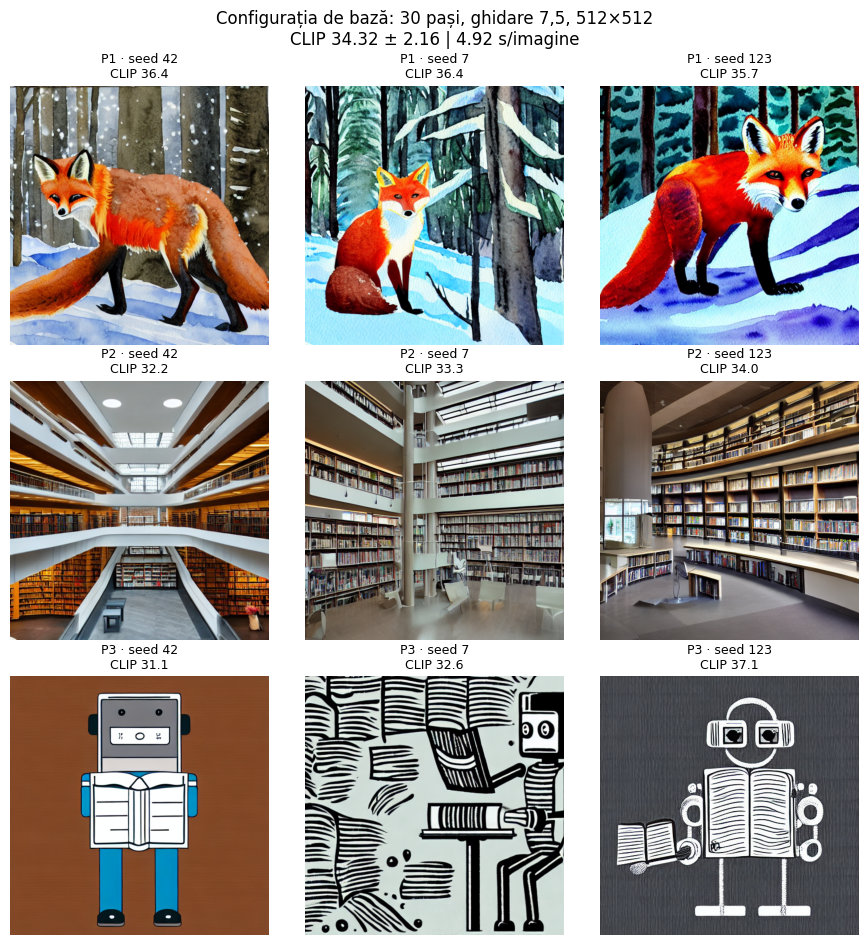

Verificare CLIP — imaginea P1/seed 42 comparată cu:
  textul P1 (corect): 36.43
  textul P3 (greșit): 13.67


In [11]:
rez_baza = ruleaza({}, "baza")
adauga_in_tabel("Bază", "30 pași, ghidare 7,5 (PNDM)", rez_baza)
arata_rezultat(rez_baza, "Configurația de bază: 30 pași, ghidare 7,5, 512×512", "grila_baza_titluri.png")

vulpe = rez_baza["images"][("P1", 42)]
print("Verificare CLIP — imaginea P1/seed 42 comparată cu:")
print(f"  textul P1 (corect): {scor_clip(vulpe, PROMPTS['P1']):.2f}")
print(f"  textul P3 (greșit): {scor_clip(vulpe, PROMPTS['P3']):.2f}")

## Sarcina 3 — Experimentul A: scara de ghidare (`guidance_scale`)

**Ghidarea fără clasificator (classifier-free guidance):** la fiecare pas, U-Net-ul prezice zgomotul de două ori, o dată **cu** text ($\epsilon_c$) și o dată **fără** ($\epsilon_u$), apoi combină cele două predicții:

$$\hat\epsilon = \epsilon_u + g\,(\epsilon_c - \epsilon_u)$$

- $g = 1$ → doar predicția condiționată. `diffusers` dezactivează atunci ghidarea și face **o singură** trecere prin U-Net, deci **timpul scade cam la jumătate**;
- $g$ mare → imaginea e împinsă puternic spre text, cu riscul de culori saturate și artefacte.

Valori testate: 1, 3, 7,5, 12, 20. Valoarea 7,5 e exact configurația de bază, așa că refolosim rezultatul ei.

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  [A_ghidare_1] P1 seed 42:    3.4 s | CLIP 16.88  (NSFW detectat -> imagine neagră!)
  [A_ghidare_1] P1 seed 7:    3.3 s | CLIP 32.95
  [A_ghidare_1] P1 seed 123:    3.3 s | CLIP 31.28
  [A_ghidare_1] P2 seed 42:    3.4 s | CLIP 29.99
  [A_ghidare_1] P2 seed 7:    3.4 s | CLIP 22.98
  [A_ghidare_1] P2 seed 123:    3.4 s | CLIP 25.09
  [A_ghidare_1] P3 seed 42:    3.3 s | CLIP 32.56
  [A_ghidare_1] P3 seed 7:    3.3 s | CLIP 21.18
  [A_ghidare_1] P3 seed 123:    3.3 s | CLIP 28.58
[A_ghidare_1] gata în 36 s
  [A_ghidare_3] P1 seed 42:    5.1 s | CLIP 35.92
  [A_ghidare_3] P1 seed 7:    5.1 s | CLIP 37.18
  [A_ghidare_3] P1 seed 123:    5.1 s | CLIP 35.66
  [A_ghidare_3] P2 seed 42:    5.1 s | CLIP 30.97
  [A_ghidare_3] P2 seed 7:    5.1 s | CLIP 32.14
  [A_ghidare_3] P2 seed 123:    5.1 s | CLIP 30.80
  [A_ghidare_3] P3 seed 42:    5.1 s | CLIP 36.42
  [A_ghidare_3] P3 seed 7:    5.1 s | CLIP 32.57
  [A_ghidare_3] P3 seed 123:    5.2 s | CLIP 35.16
[A_ghidare_3] gata în 52 s
  [A_ghida

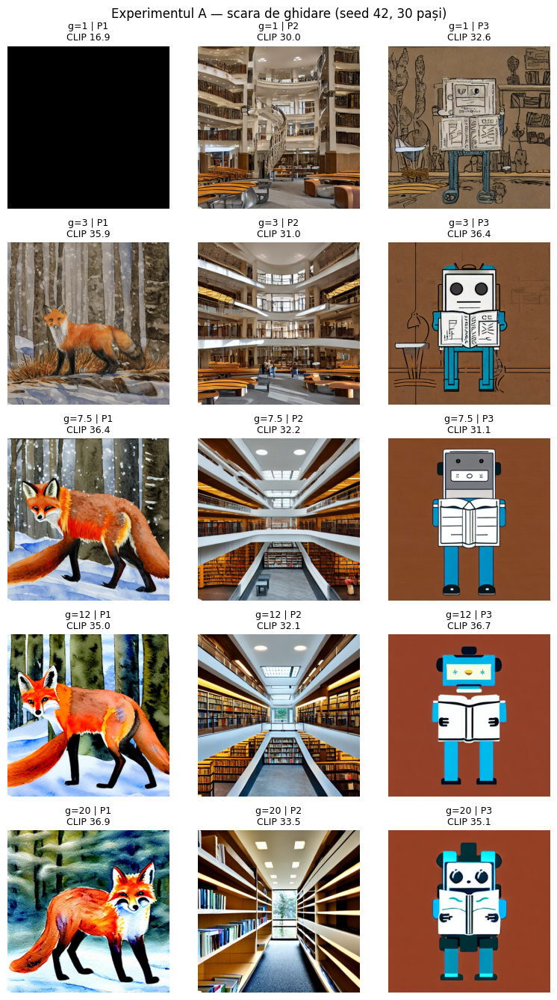

In [12]:
VALORI_A = [1, 3, 7.5, 12, 20]
rez_A = {}
for g in VALORI_A:
    rez_A[g] = rez_baza if g == BASE["guidance"] else ruleaza({"guidance": g}, f"A_ghidare_{g}")
    if g != BASE["guidance"]:
        adauga_in_tabel("A", f"ghidare {g}", rez_A[g])

compara([rez_A[g] for g in VALORI_A], [f"g={g}" for g in VALORI_A],
        "Experimentul A — scara de ghidare (seed 42, 30 pași)", "comparatie_A_ghidare.png")

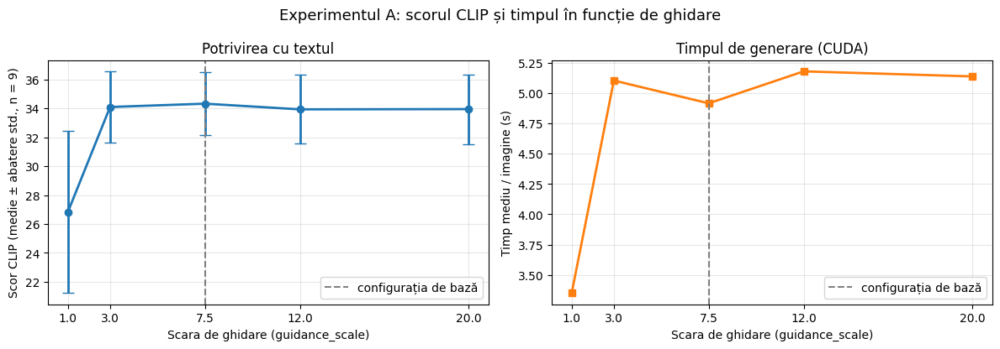

In [13]:
grafic(VALORI_A, [rez_A[g] for g in VALORI_A], "Scara de ghidare (guidance_scale)",
       "Experimentul A: scorul CLIP și timpul în funcție de ghidare", "grafic_A_ghidare.png", x_baza=7.5)

## Experimentul B: numărul de pași (`num_inference_steps`)

Mai mulți pași înseamnă o discretizare mai fină a procesului invers. Timpul crește **liniar** cu numărul de pași, dar calitatea se saturează de la un punct. Valori testate: 5, 10, 20, 50. Punctul de 30 de pași (configurația de bază) apare și el pe grafic.

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  [B_pasi_5] P1 seed 42:    1.2 s | CLIP 16.88  (NSFW detectat -> imagine neagră!)
  [B_pasi_5] P1 seed 7:    1.2 s | CLIP 33.16
  [B_pasi_5] P1 seed 123:    1.2 s | CLIP 36.35
  [B_pasi_5] P2 seed 42:    1.2 s | CLIP 32.96
  [B_pasi_5] P2 seed 7:    1.2 s | CLIP 30.32
  [B_pasi_5] P2 seed 123:    1.2 s | CLIP 30.76
  [B_pasi_5] P3 seed 42:    1.2 s | CLIP 37.25


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  [B_pasi_5] P3 seed 7:    1.2 s | CLIP 18.90  (NSFW detectat -> imagine neagră!)
  [B_pasi_5] P3 seed 123:    1.2 s | CLIP 31.81
[B_pasi_5] gata în 17 s


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


  [B_pasi_10] P1 seed 42:    2.1 s | CLIP 16.88  (NSFW detectat -> imagine neagră!)
  [B_pasi_10] P1 seed 7:    2.1 s | CLIP 37.87
  [B_pasi_10] P1 seed 123:    2.1 s | CLIP 36.25
  [B_pasi_10] P2 seed 42:    2.1 s | CLIP 31.54
  [B_pasi_10] P2 seed 7:    2.1 s | CLIP 33.11
  [B_pasi_10] P2 seed 123:    2.1 s | CLIP 33.62
  [B_pasi_10] P3 seed 42:    2.1 s | CLIP 31.62
  [B_pasi_10] P3 seed 7:    2.1 s | CLIP 28.91
  [B_pasi_10] P3 seed 123:    2.0 s | CLIP 34.63
[B_pasi_10] gata în 25 s
  [B_pasi_20] P1 seed 42:    3.6 s | CLIP 36.44
  [B_pasi_20] P1 seed 7:    3.6 s | CLIP 36.42
  [B_pasi_20] P1 seed 123:    3.6 s | CLIP 36.01
  [B_pasi_20] P2 seed 42:    3.5 s | CLIP 31.42
  [B_pasi_20] P2 seed 7:    3.5 s | CLIP 33.95
  [B_pasi_20] P2 seed 123:    3.5 s | CLIP 34.17
  [B_pasi_20] P3 seed 42:    3.5 s | CLIP 36.97
  [B_pasi_20] P3 seed 7:    3.5 s | CLIP 32.32
  [B_pasi_20] P3 seed 123:    3.5 s | CLIP 37.21
[B_pasi_20] gata în 38 s
  [B_pasi_50] P1 seed 42:    8.3 s | CLIP 36.52
  

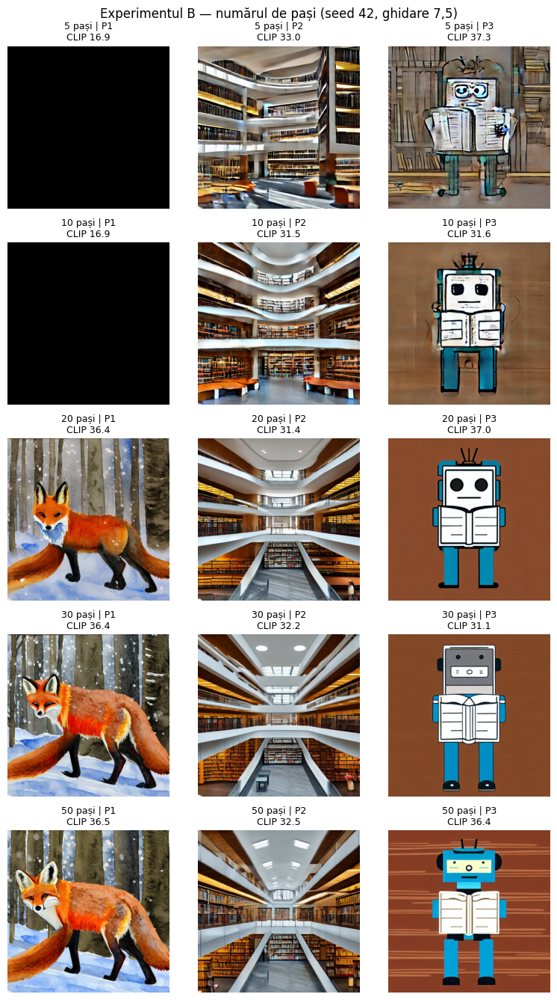

In [14]:
VALORI_B = [5, 10, 20, 50]
rez_B = {}
for n in VALORI_B:
    rez_B[n] = ruleaza({"steps": n}, f"B_pasi_{n}")
    adauga_in_tabel("B", f"{n} pași", rez_B[n])
rez_B[30] = rez_baza

X_B = sorted(rez_B)
compara([rez_B[n] for n in X_B], [f"{n} pași" for n in X_B],
        "Experimentul B — numărul de pași (seed 42, ghidare 7,5)", "comparatie_B_pasi.png")

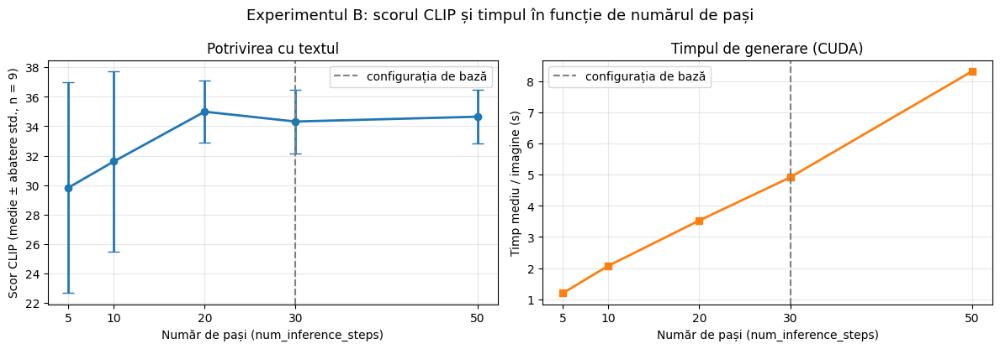

  5 pași:    1.20 s/imagine  ->  0.239 s/pas
 10 pași:    2.07 s/imagine  ->  0.207 s/pas
 20 pași:    3.53 s/imagine  ->  0.177 s/pas
 30 pași:    4.92 s/imagine  ->  0.164 s/pas
 50 pași:    8.33 s/imagine  ->  0.167 s/pas


In [15]:
grafic(X_B, [rez_B[n] for n in X_B], "Număr de pași (num_inference_steps)",
       "Experimentul B: scorul CLIP și timpul în funcție de numărul de pași", "grafic_B_pasi.png", x_baza=30)

# Timpul pe pas ar trebui să fie aproximativ constant (dependență liniară)
for n in X_B:
    print(f"{n:3d} pași: {rez_B[n]['time_mean']:7.2f} s/imagine  ->  {rez_B[n]['time_mean'] / n:.3f} s/pas")

## Experimentul C: metoda de eșantionare (`pipe.scheduler`)

Același U-Net antrenat poate fi folosit cu metode de eșantionare diferite, pentru că acestea schimbă doar **felul în care facem pașii**, nu rețeaua:
- **DDIM**: deterministic, sare peste pași (l-ați implementat în Laboratorul 4);
- **DPM-Solver (multistep)**: rezolvitor de ordin superior pentru ecuația diferențială a procesului invers, foarte bun la 10–20 de pași;
- **Euler**: metoda Euler aplicată aceleiași ecuații, în parametrizarea pe σ (Karras et al.).

Fiecare la 10 și 30 de pași. Schimbarea se face cu `X.from_config(pipe.scheduler.config)`, în `set_scheduler`. Ca referință, schedulerul implicit (PNDM) la 10 pași este `B_pasi_10`, iar la 30 de pași este configurația de bază.

  [C_DDIM_10] P1 seed 42:    1.8 s | CLIP 36.31
  [C_DDIM_10] P1 seed 7:    1.8 s | CLIP 36.60
  [C_DDIM_10] P1 seed 123:    1.9 s | CLIP 33.66
  [C_DDIM_10] P2 seed 42:    1.9 s | CLIP 32.01
  [C_DDIM_10] P2 seed 7:    1.9 s | CLIP 32.32
  [C_DDIM_10] P2 seed 123:    1.9 s | CLIP 32.39
  [C_DDIM_10] P3 seed 42:    1.9 s | CLIP 35.54
  [C_DDIM_10] P3 seed 7:    1.9 s | CLIP 32.31
  [C_DDIM_10] P3 seed 123:    1.9 s | CLIP 37.01
[C_DDIM_10] gata în 24 s
  [C_DDIM_30] P1 seed 42:    5.3 s | CLIP 36.71
  [C_DDIM_30] P1 seed 7:    5.1 s | CLIP 36.70
  [C_DDIM_30] P1 seed 123:    5.1 s | CLIP 35.34
  [C_DDIM_30] P2 seed 42:    5.0 s | CLIP 31.89
  [C_DDIM_30] P2 seed 7:    4.9 s | CLIP 33.43
  [C_DDIM_30] P2 seed 123:    4.9 s | CLIP 34.17
  [C_DDIM_30] P3 seed 42:    4.9 s | CLIP 37.81
  [C_DDIM_30] P3 seed 7:    4.9 s | CLIP 32.74
  [C_DDIM_30] P3 seed 123:    4.9 s | CLIP 37.35
[C_DDIM_30] gata în 51 s
  [C_DPMSolver_10] P1 seed 42:    1.8 s | CLIP 35.87
  [C_DPMSolver_10] P1 seed 7:    

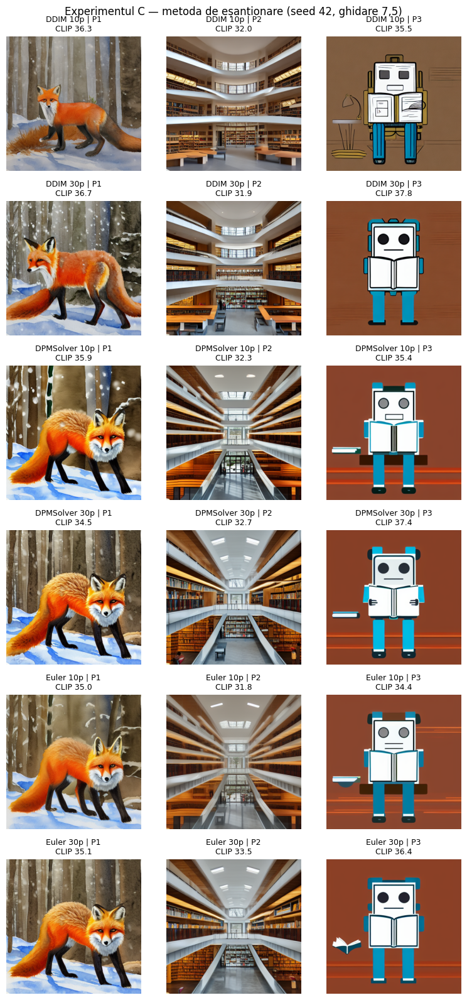

In [16]:
PASI_C = [10, 30]
rez_C = {}
for nume in SCHEDULERS:
    for n in PASI_C:
        rez_C[(nume, n)] = ruleaza({"scheduler": nume, "steps": n}, f"C_{nume}_{n}")
        adauga_in_tabel("C", f"{nume}, {n} pași", rez_C[(nume, n)])

chei = [(nume, n) for nume in SCHEDULERS for n in PASI_C]
compara([rez_C[k] for k in chei], [f"{k[0]} {k[1]}p" for k in chei],
        "Experimentul C — metoda de eșantionare (seed 42, ghidare 7,5)", "comparatie_C_scheduler.png")

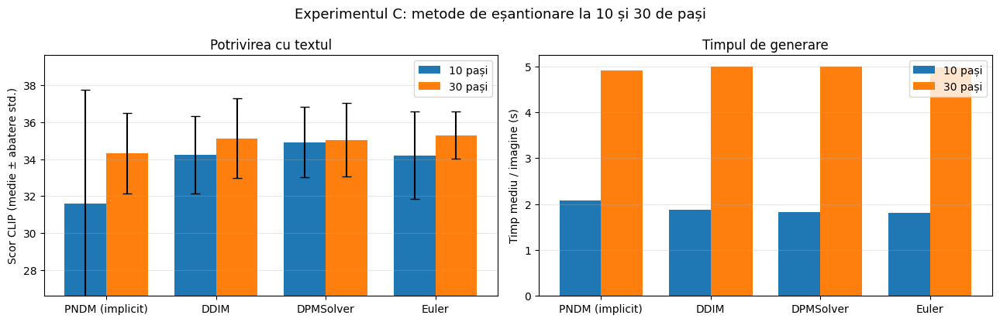

In [17]:
# Grafic cu bare grupate: scorul CLIP (± abatere) și timpul, pentru fiecare metodă, la 10 și 30 de pași
metode = ["PNDM (implicit)"] + list(SCHEDULERS)
ref = {("PNDM (implicit)", 10): rez_B[10], ("PNDM (implicit)", 30): rez_baza}
toate = {**ref, **rez_C}

x = np.arange(len(metode)); w = 0.38
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.2))
for i, n in enumerate(PASI_C):
    m = [toate[(mt, n)]["clip_mean"] for mt in metode]
    s = [toate[(mt, n)]["clip_std"] for mt in metode]
    t = [toate[(mt, n)]["time_mean"] for mt in metode]
    ax1.bar(x + (i - 0.5) * w, m, w, yerr=s, capsize=4, label=f"{n} pași")
    ax2.bar(x + (i - 0.5) * w, t, w, label=f"{n} pași")
ax1.set_xticks(x, metode); ax1.set_ylabel("Scor CLIP (medie ± abatere std.)"); ax1.set_title("Potrivirea cu textul")
ax1.set_ylim(min(toate[k]["clip_mean"] for k in toate) - 5, None)
ax2.set_xticks(x, metode); ax2.set_ylabel("Timp mediu / imagine (s)"); ax2.set_title("Timpul de generare")
for ax in (ax1, ax2):
    ax.legend(); ax.grid(axis="y", alpha=0.3)
fig.suptitle("Experimentul C: metode de eșantionare la 10 și 30 de pași", fontsize=13)
fig.tight_layout(); fig.savefig(OUT / "grafic_C_scheduler.png", dpi=130, bbox_inches="tight"); plt.show()

## Experimentul D: seed-ul (`generator`)

Seed-ul determină **zgomotul latent inițial** $z_T$, iar de el depinde compoziția imaginii. Procedăm așa:
1. generăm P1 cu **4 seed-uri noi** (0, 1, 2024, 31337) și vedem cât variază imaginea și scorul CLIP;
2. generăm P1 cu seed-ul **42 de două ori**, în rulări separate, și verificăm numeric că imaginile sunt identice: **diferența medie absolută între pixeli** trebuie să fie 0 (sau foarte aproape de 0 pe GPU).

Pentru contrast, calculăm și diferența dintre seed 42 și seed 7, care trebuie să fie mare. Imaginile sunt salvate ca PNG (fără pierderi), deci comparația rămâne valabilă și după reîncărcarea din cache.

  [D_seeduri_P1] P1 seed 0:    5.1 s | CLIP 35.89
  [D_seeduri_P1] P1 seed 1:    5.3 s | CLIP 33.45
  [D_seeduri_P1] P1 seed 2024:    5.4 s | CLIP 36.22
  [D_seeduri_P1] P1 seed 31337:    5.5 s | CLIP 35.96
[D_seeduri_P1] gata în 24 s


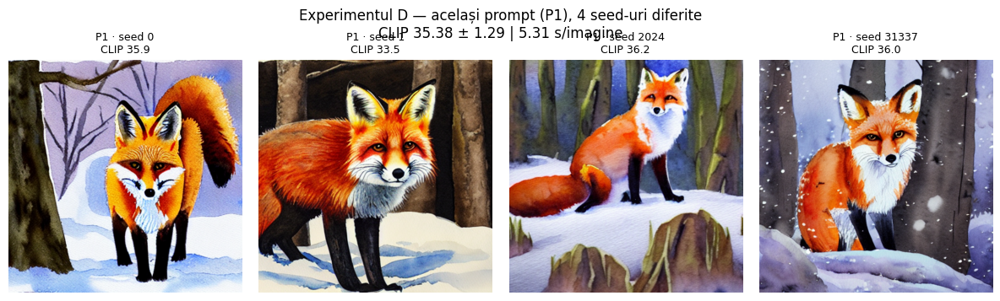

In [18]:
SEEDS_D = [0, 1, 2024, 31337]
P1_ONLY = {"P1": PROMPTS["P1"]}

rez_D = ruleaza({}, "D_seeduri_P1", prompts=P1_ONLY, seeds=SEEDS_D)
adauga_in_tabel("D", f"P1, seed-uri {SEEDS_D}", rez_D)
arata_rezultat(rez_D, "Experimentul D — același prompt (P1), 4 seed-uri diferite", "comparatie_D_seeduri.png")

[D_seed42_rularea1] încărcat din cache (1 imagini)
[D_seed42_rularea2] încărcat din cache (1 imagini)
Diferența medie între pixeli (scala 0–255):
  seed 42, rularea 1 vs rularea 2       : 0.0000
  seed 42, rularea 1 vs grila de bază    : 0.0000
  seed 42 vs seed 7 (contrast)           : 82.8481
  Identice pixel cu pixel (rularea 1 vs 2): True


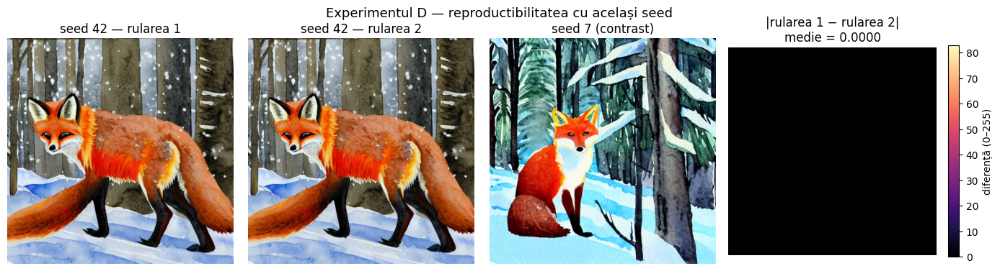

In [20]:
rez_D42_1 = ruleaza({}, "D_seed42_rularea1", prompts=P1_ONLY, seeds=[42])
rez_D42_2 = ruleaza({}, "D_seed42_rularea2", prompts=P1_ONLY, seeds=[42])

def arr(img):
    return np.asarray(img, dtype=np.float64)

img1 = arr(rez_D42_1["images"][("P1", 42)])
img2 = arr(rez_D42_2["images"][("P1", 42)])
img_baza42 = arr(rez_baza["images"][("P1", 42)])
img_baza7 = arr(rez_baza["images"][("P1", 7)])

d_12 = np.abs(img1 - img2).mean()
d_1b = np.abs(img1 - img_baza42).mean()
d_42_7 = np.abs(img_baza42 - img_baza7).mean()
print(f"Diferența medie între pixeli (scala 0–255):")
print(f"  seed 42, rularea 1 vs rularea 2       : {d_12:.4f}")
print(f"  seed 42, rularea 1 vs grila de bază    : {d_1b:.4f}")
print(f"  seed 42 vs seed 7 (contrast)           : {d_42_7:.4f}")
print("  Identice pixel cu pixel (rularea 1 vs 2):", bool(np.array_equal(img1, img2)))

adauga_in_tabel("D", "P1, seed 42 (rularea 1)", rez_D42_1)
adauga_in_tabel("D", "P1, seed 42 (rularea 2)", rez_D42_2,
                observatii=f"dif. medie pixeli față de rularea 1 = {d_12:.4f}; față de seed 7 = {d_42_7:.1f}")

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for ax, im, t in zip(axes, [img1, img2, img_baza7],
                     ["seed 42 — rularea 1", "seed 42 — rularea 2", "seed 7 (contrast)"]):
    ax.imshow(im.astype(np.uint8)); ax.set_title(t); ax.axis("off")
h = axes[3].imshow(np.abs(img1 - img2).mean(axis=2), cmap="magma", vmin=0, vmax=max(1, d_42_7))
axes[3].set_title(f"|rularea 1 − rularea 2|\nmedie = {d_12:.4f}"); axes[3].axis("off")
fig.colorbar(h, ax=axes[3], fraction=0.046, label="diferență (0–255)")
fig.suptitle("Experimentul D — reproductibilitatea cu același seed", fontsize=13)
fig.tight_layout(); fig.savefig(OUT / "comparatie_D_seed42.png", dpi=120, bbox_inches="tight"); plt.show()

## Experimentul E: promptul negativ (`negative_prompt`)

Când dăm un prompt negativ, predicția „necondiționată” $\epsilon_u$ din formula ghidării se calculează **cu textul negativ** în loc de textul gol. Ghidarea împinge astfel imaginea **departe** de conceptele respective. Comparăm configurația fără prompt negativ (cea de bază) cu „blurry, low quality, text, watermark”. Costul de calcul e același, pentru că se fac tot două treceri prin U-Net.

  [E_prompt_negativ] P1 seed 42:    5.0 s | CLIP 34.27
  [E_prompt_negativ] P1 seed 7:    5.1 s | CLIP 36.26
  [E_prompt_negativ] P1 seed 123:    5.3 s | CLIP 35.95
  [E_prompt_negativ] P2 seed 42:    6.0 s | CLIP 32.54
  [E_prompt_negativ] P2 seed 7:    5.5 s | CLIP 34.06
  [E_prompt_negativ] P2 seed 123:    5.4 s | CLIP 33.06
  [E_prompt_negativ] P3 seed 42:    5.3 s | CLIP 39.27
  [E_prompt_negativ] P3 seed 7:    5.2 s | CLIP 32.58
  [E_prompt_negativ] P3 seed 123:    5.1 s | CLIP 31.68
[E_prompt_negativ] gata în 56 s


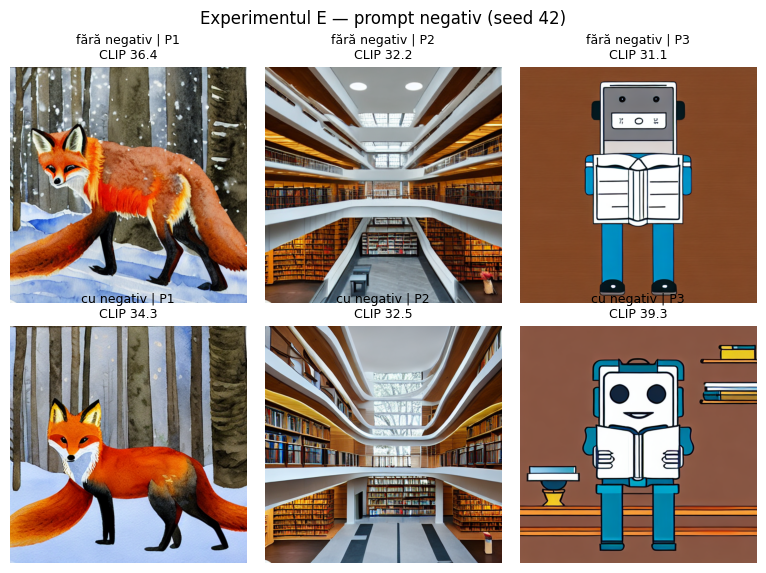

,Prompt,fără negativ,cu negativ,diferență
0,P1,36.19,35.49,-0.70
1,P2,33.18,33.22,0.04
2,P3,33.60,34.51,0.92


In [21]:
NEG = "blurry, low quality, text, watermark"
rez_E = ruleaza({"negative_prompt": NEG}, "E_prompt_negativ")
adauga_in_tabel("E", "fără prompt negativ", rez_baza)
adauga_in_tabel("E", f"negativ: „{NEG}”", rez_E)

compara([rez_baza, rez_E], ["fără negativ", "cu negativ"],
        "Experimentul E — prompt negativ (seed 42)", "comparatie_E_negativ.png")

# Scorul CLIP pe fiecare prompt, cu și fără prompt negativ
rows_E = []
for pid in PROMPTS:
    a = [_clip_of(rez_baza, pid, s) for s in SEEDS]
    b = [_clip_of(rez_E, pid, s) for s in SEEDS]
    rows_E.append({"Prompt": pid, "fără negativ": round(np.mean(a), 2), "cu negativ": round(np.mean(b), 2),
                   "diferență": round(np.mean(b) - np.mean(a), 2)})
display(pd.DataFrame(rows_E))

## Tabelul de rezultate

In [22]:

COLOANE = ["Experiment", "Valoare", "Scor CLIP (medie ± abatere)", "Timp / imagine (s)"]
df = pd.DataFrame(list(TABEL.values()))
df[COLOANE].to_csv(OUT / "tabel_rezultate.csv", index=False)

def df_to_md(d):
    linii = ["| " + " | ".join(d.columns) + " |", "|" + "---|" * len(d.columns)]
    linii += ["| " + " | ".join(str(v) for v in row) + " |" for row in d.itertuples(index=False)]
    return "\n".join(linii)

(OUT / "tabel_rezultate.md").write_text(df_to_md(df[COLOANE]), encoding="utf-8")
pd.set_option("display.max_colwidth", 80)
display(df[COLOANE])

,Experiment,Valoare,Scor CLIP (medie ± abatere),Timp / imagine (s)
0,Bază,"30 pași, ghidare 7,5 (PNDM)",34.32 ± 2.16,4.92
1,A,ghidare 1,26.83 ± 5.61,3.35
2,A,ghidare 3,34.09 ± 2.47,5.11
3,A,ghidare 12,33.93 ± 2.37,5.18
4,A,ghidare 20,33.94 ± 2.41,5.14
5,B,5 pași,29.82 ± 7.16,1.20
6,B,10 pași,31.60 ± 6.13,2.07
7,B,20 pași,34.99 ± 2.11,3.53
8,B,50 pași,34.65 ± 1.82,8.33
9,C,"DDIM, 10 pași",34.24 ± 2.10,1.88


## Sarcina 4. Recomandarea

Celula de mai jos sortează configurațiile după scorul CLIP și după timp, ca bază pentru recomandare. Atenție la interpretare:
- o diferență de scor CLIP **mai mică decât abaterea standard** nu e semnificativă (n = 9 imagini);
- scorul CLIP nu măsoară estetica sau artefactele, deci recomandarea trebuie să țină cont și de grile;
- pragul de **2 secunde** se referă la hardware-ul de producție (de regulă un GPU). Dacă rulați pe CPU, nicio configurație nu va fi sub 2 s. În cazul acesta, alegeți configurația cu cei mai puțini pași care încă dă imagini bune și argumentați cu timpul pe pas (pe GPU timpul scalează la fel, liniar cu numărul de pași).

In [23]:
dfr = df.drop_duplicates(subset=["CLIP medie", "Timp / imagine (s)"]).copy()
dfr["s / pas (aprox.)"] = np.nan
cols_vez = ["Experiment", "Valoare", "Scor CLIP (medie ± abatere)", "Timp / imagine (s)"]

print("Top 5 după scorul CLIP mediu:")
display(dfr.sort_values("CLIP medie", ascending=False)[cols_vez].head(5))

print("Cele mai rapide 6 configurații:")
display(dfr.sort_values("Timp / imagine (s)")[cols_vez].head(6))

sub2 = dfr[dfr["Timp / imagine (s)"] < 2.0]
if len(sub2):
    print("Configurații sub 2 s / imagine, ordonate după CLIP:")
    display(sub2.sort_values("CLIP medie", ascending=False)[cols_vez])
else:
    print(f"Pe acest hardware ({DEVICE}) nicio configurație nu e sub 2 s/imagine. "
          "Argumentați varianta rapidă prin numărul minim de pași cu calitate acceptabilă.")

Top 5 după scorul CLIP mediu:


,Experiment,Valoare,Scor CLIP (medie ± abatere),Timp / imagine (s)
16,D,"P1, seed 42 (rularea 1)",36.43 ± 0.00,5.32
17,D,"P1, seed 42 (rularea 2)",36.43 ± 0.00,5.21
15,D,"P1, seed-uri [0, 1, 2024, 31337]",35.38 ± 1.29,5.31
14,C,"Euler, 30 pași",35.30 ± 1.27,4.99
10,C,"DDIM, 30 pași",35.13 ± 2.15,4.99


Cele mai rapide 6 configurații:


,Experiment,Valoare,Scor CLIP (medie ± abatere),Timp / imagine (s)
5,B,5 pași,29.82 ± 7.16,1.20
13,C,"Euler, 10 pași",34.21 ± 2.38,1.81
11,C,"DPMSolver, 10 pași",34.92 ± 1.91,1.82
9,C,"DDIM, 10 pași",34.24 ± 2.10,1.88
6,B,10 pași,31.60 ± 6.13,2.07
1,A,ghidare 1,26.83 ± 5.61,3.35


Configurații sub 2 s / imagine, ordonate după CLIP:


,Experiment,Valoare,Scor CLIP (medie ± abatere),Timp / imagine (s)
11,C,"DPMSolver, 10 pași",34.92 ± 1.91,1.82
9,C,"DDIM, 10 pași",34.24 ± 2.10,1.88
13,C,"Euler, 10 pași",34.21 ± 2.38,1.81
5,B,5 pași,29.82 ± 7.16,1.20


## Bonus (+1 punct): img2img și legătura cu procesul direct din Laboratorul 4

`StableDiffusionImg2ImgPipeline` nu pornește din zgomot pur, ci dintr-o **imagine existentă**:
1. imaginea e codificată de VAE în latentul $z_0$;
2. se aplică **procesul direct** din Laboratorul 4 până la pasul $t_0 \approx \text{strength}\cdot T$:
   $z_{t_0} = \sqrt{\bar\alpha_{t_0}}\,z_0 + \sqrt{1-\bar\alpha_{t_0}}\,\epsilon$ (exact `q_sample`);
3. se rulează procesul invers doar de la $t_0$, adică aproximativ `strength × num_inference_steps` pași.

`strength` mic înseamnă mult semnal păstrat ($\sqrt{\bar\alpha_{t_0}}$ mare) și modificări doar de stil sau detaliu. `strength` aproape de 1 înseamnă că imaginea inițială aproape dispare și obținem practic text→imagine.

Refolosim componentele deja încărcate (`pipe.components`, fără a reîncărca modelul) și schedulerul DDIM. Pornim de la imaginea de bază P2 / seed 42 (biblioteca) și cerem o versiune în acuarelă.

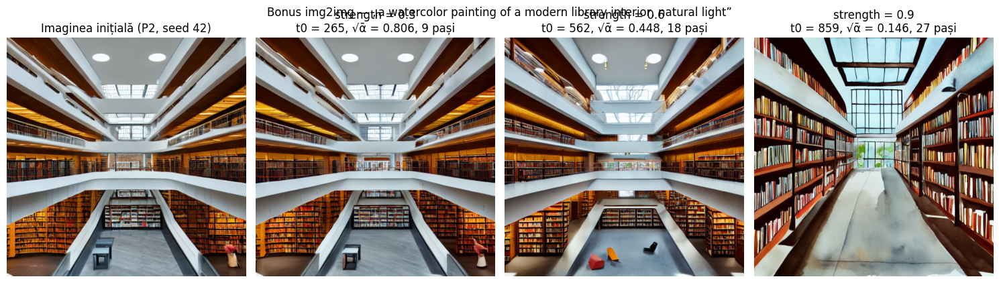

,strength,pași rulați,t0,sqrt(alpha_bar_t0),dif. pixeli față de inițială,CLIP (prompt nou),CLIP (P2 original)
0,0.3,9,265,0.806,16.7,27.43,32.08
1,0.6,18,562,0.448,30.6,27.92,32.34
2,0.9,27,859,0.146,64.3,35.91,30.10


In [24]:
img2img = StableDiffusionImg2ImgPipeline(**pipe.components)
img2img.scheduler = DDIMScheduler.from_config(DEFAULT_SCHEDULER_CONFIG)
img2img.set_progress_bar_config(disable=True)

init_img = rez_baza["images"][("P2", 42)]
PROMPT_I2I = "a watercolor painting of a modern library interior, natural light"
STRENGTHS = [0.3, 0.6, 0.9]
PASI_I2I = 30
folder_i2i = OUT / "bonus_img2img"; folder_i2i.mkdir(exist_ok=True)

# Pasul de pornire t0 și semnalul păstrat sqrt(alpha_bar_t0) — legătura cu q_sample din Laboratorul 4
img2img.scheduler.set_timesteps(PASI_I2I)
ts = img2img.scheduler.timesteps
acp = img2img.scheduler.alphas_cumprod

rez_i2i = []
for s in STRENGTHS:
    n_pasi = min(int(PASI_I2I * s), PASI_I2I)
    t0 = int(ts[PASI_I2I - n_pasi])
    semnal = float(acp[t0].sqrt())
    path = folder_i2i / f"strength_{s}.png"
    if path.exists() and not RECOMPUTE:
        img = Image.open(path).convert("RGB")
    else:
        img = img2img(prompt=PROMPT_I2I, image=init_img, strength=s, num_inference_steps=PASI_I2I,
                      guidance_scale=7.5, generator=make_generator(42)).images[0]
        img.save(path)
    rez_i2i.append({"strength": s, "pași rulați": n_pasi, "t0": t0, "sqrt(alpha_bar_t0)": round(semnal, 3),
                    "dif. pixeli față de inițială": round(float(np.abs(arr(img) - arr(init_img)).mean()), 1),
                    "CLIP (prompt nou)": round(scor_clip(img, PROMPT_I2I), 2),
                    "CLIP (P2 original)": round(scor_clip(img, PROMPTS["P2"]), 2), "img": img})

fig, axes = plt.subplots(1, 4, figsize=(15, 4.3))
axes[0].imshow(init_img); axes[0].set_title("Imaginea inițială (P2, seed 42)"); axes[0].axis("off")
for ax, r in zip(axes[1:], rez_i2i):
    ax.imshow(r["img"]); ax.axis("off")
    ax.set_title(f"strength = {r['strength']}\nt0 = {r['t0']}, √ᾱ = {r['sqrt(alpha_bar_t0)']}, {r['pași rulați']} pași")
fig.suptitle(f"Bonus img2img — „{PROMPT_I2I}”", fontsize=12)
fig.tight_layout(); fig.savefig(OUT / "bonus_img2img.png", dpi=120, bbox_inches="tight"); plt.show()

display(pd.DataFrame([{k: v for k, v in r.items() if k != "img"} for r in rez_i2i]))

**Interpretare bonus**: pe măsură ce `strength` crește, $t_0$ crește, $\sqrt{\bar\alpha_{t_0}}$ scade, deci din imaginea inițială rămâne tot mai puțin semnal. Diferența față de imaginea inițială crește, iar scorul CLIP față de promptul nou crește. Este exact graficul $\sqrt{\bar\alpha_t}$ din Sarcina 2 a Laboratorului 4: `strength` alege pe ce punct al curbei pornim procesul invers.

## Întrebări de control — Laboratorul 5

*Răspunsurile de mai jos sunt o bază teoretică. Înlocuiți marcajele **[completați]** cu valorile și exemplele din experimentele voastre.*

**1. Ce se întâmplă cu imaginea la ghidare 1 și la ghidare 20? De ce?**
La g = 1, formula $\hat\epsilon = \epsilon_u + g(\epsilon_c-\epsilon_u)$ se reduce la $\epsilon_c$: nu mai există ghidare suplimentară spre text. Imaginile sunt mai vagi, mai puțin coerente și mai slab legate de prompt (CLIP [completați]). `diffusers` face atunci o singură trecere prin U-Net, deci generarea e aproape de două ori mai rapidă ([completați] s față de [completați] s). La g = 20, diferența $(\epsilon_c-\epsilon_u)$ este amplificată puternic și predicția iese din zona datelor de antrenare: culori suprasaturate, contrast exagerat, detalii „arse” și artefacte ([completați exemplu]). Scorul CLIP nu crește la nesfârșit: [completați unde se oprește].

**2. De la câți pași nu mai vedeți îmbunătățiri clare? Coincide cu scorul CLIP?**
Vizual: de la aproximativ [completați] pași. Scorul CLIP: [completați]; diferențele dintre 20, 30 și 50 de pași sunt [mai mici / mai mari] decât abaterea standard. CLIP reacționează mai ales la *conținut* (dacă vulpea și zăpada există), nu la finețea detaliilor, așa că se poate satura mai devreme decât percepția vizuală sau poate fluctua în limita zgomotului.

**3. De ce metodele DPM-Solver și Euler se descurcă mai bine la puțini pași decât DDPM-ul din Laboratorul 4?**
Eșantionarea DDPM este un lanț Markov stocastic în care fiecare pas aproximează o tranziție *mică* printr-o gaussiană. Aproximarea e bună doar dacă pașii sunt mici, deci e nevoie de ~1000 de pași. DDIM, Euler și DPM-Solver privesc procesul invers ca pe o **ecuație diferențială ordinară** (probability flow ODE), deterministă, pe care o pot rezolva cu pași mari. Euler e o metodă de ordinul 1, cu pași bine distribuiți pe σ. DPM-Solver rezolvă exact partea liniară a ecuației și aproximează restul cu o metodă de ordin superior, refolosind predicțiile de la pașii anteriori (multistep). Eroarea de discretizare e mult mai mică, deci 10–20 de pași sunt suficienți. Rezultatele noastre: [completați].

**4. De ce același seed dă aceeași imagine? La ce folosește asta în practică?**
Seed-ul inițializează generatorul pseudo-aleator, care produce zgomotul latent inițial $z_T$ (și zgomotul de la fiecare pas, la schedulerele stocastice). Cu aceleași ponderi, același prompt, aceiași parametri și același hardware și aceeași precizie, restul calculului e determinist, deci imaginea e identică (diferența măsurată: [completați]). În practică: reproductibilitate (rezultate verificabile, teste de regresie), comparații corecte A/B în care se schimbă un singur parametru (exact ce am făcut aici), rafinarea promptului păstrând compoziția, depanare, regenerarea unei imagini aprobate de client.

**5. Ce nu măsoară scorul CLIP? Dați un exemplu din imaginile voastre.**
CLIP măsoară doar similaritatea semantică globală dintre imagine și text. Nu măsoară: calitatea estetică, claritatea sau zgomotul, artefactele anatomice (labe sau degete deformate), relațiile spațiale și numărarea obiectelor, textul randat corect, diversitatea, fotorealismul. Poate fi și „păcălit”, de exemplu de imagini suprasaturate care exagerează conceptele din prompt. Exemplu din experimente: [completați, de exemplu o imagine cu 5 pași sau ghidare 20 care are un scor CLIP apropiat de configurația de bază, deși arată vizibil mai rău].

**6. Ce riscuri etice sau juridice vedeți în folosirea unor astfel de modele într-o companie?**
- **Drepturi de autor:** datele de antrenare (LAION) conțin opere protejate; imaginile pot imita stilul unor artiști sau pot reproduce aproape identic opere ori mărci înregistrate. Statutul juridic al imaginilor generate (protecție, proprietate) este încă neclar în multe jurisdicții.
- **Licența modelului:** SD 1.5 e distribuit sub licența CreativeML OpenRAIL-M, care interzice anumite utilizări. Compania trebuie să verifice și să respecte condițiile.
- **Deepfake-uri și dezinformare:** imagini false cu persoane reale, încălcarea dreptului la imagine și a vieții private (GDPR).
- **Prejudecăți (bias):** stereotipuri de gen, etnie sau vârstă preluate din datele de antrenare.
- **Conținut nepotrivit:** filtrele (safety checker) nu sunt perfecte.
- **Transparență și reglementare:** obligația de a marca conținutul generat de AI (de exemplu prin AI Act în UE), responsabilitatea pentru ce se publică, revizia umană a rezultatelor.